In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Romanized-Telugu-NLP"
)

CMTET_FILE = (
    PROJECT_DIR
    / "data/raw/cmtet/codemix_sentiment_data.txt"
)

# Verify that the file exists
assert CMTET_FILE.exists(), (
    f"CMTET file not found: {CMTET_FILE}"
)

print("CMTET file found!")
print("File size:", round(CMTET_FILE.stat().st_size / (1024**2), 2), "MB")

CMTET file found!
File size: 3.58 MB


In [3]:
with CMTET_FILE.open(
    "r", encoding="utf-8", errors="replace"
) as file:
    for line_number, line in enumerate(file, start=1):
        if line_number > 30:
            break

        print(f"{line_number:02d}: {line.rstrip()!r}")

01: "NTL: We need Mr chari 's review on master"
02: 'en en univ univ univ en en en'
03: ''
04: ''
05: 'NEG: worst government . #YSRCP chala chethha ga paripalana chesthumdhi .'
06: 'en en univ univ te te te te te univ'
07: ''
08: ''
09: 'NEG: bayya nuvvu emina cheppu kani bagoledu ani cheppaku entha kastapadi thestharu'
10: 'te te te te te te te te te te te'
11: ''
12: ''
13: 'POS: Dube gadini vadilesi manchhi Pani chesaru @RCBTweets 👍'
14: 'ne te te te te te univ univ'
15: ''
16: ''
17: "POS: I came to watch thyview 's review crying after watching dil bechara . Movie felt very emotional . Did not cry for any movie but this movie made me feel personal and made me cry for hours . Miss you sushant . And last quote in movie `` we do n't get to decide to when born or when die , but we can decide how to live our life `` this quote is like made for sushant , and the word 'seri ' man literally cried . Love you 300 sushant ."
18: 'en en en en univ univ en en en en te te univ en en en en univ e

Count lines and inspect the labels

In [4]:
from collections import Counter

with CMTET_FILE.open(
    "r", encoding="utf-8", errors="replace"
) as file:
    lines = [line.rstrip("\n\r") for line in file]

print("Total lines:", len(lines))
print("Blank lines:", sum(not line.strip() for line in lines))
print("Non-empty lines:", sum(bool(line.strip()) for line in lines))

# Count lines beginning with a possible sentiment label
label_counts = Counter()

for line in lines:
    stripped = line.strip()

    if ":" in stripped:
        possible_label = stripped.split(":", 1)[0].strip()

        if possible_label in {"POS", "NEG", "NTL"}:
            label_counts[possible_label] += 1

print("\nPossible sentiment-labelled lines:")
for label, count in sorted(label_counts.items()):
    print(f"{label}: {count}")

Total lines: 79471
Blank lines: 39735
Non-empty lines: 39736

Possible sentiment-labelled lines:
NEG: 7717
NTL: 4222
POS: 7929


Before parsing the dataset, we need to answer three questions:
1. Does each sentence consistently have a corresponding language-tag line?
2. Do the number of sentence tokens and language tags match?
3. Are there malformed or unusual records that need special handling?

Run the structure validation

In [5]:
from pathlib import Path
from collections import Counter

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Romanized-Telugu-NLP"
)

CMTET_FILE = (
    PROJECT_DIR
    / "data/raw/cmtet/codemix_sentiment_data.txt"
)

with CMTET_FILE.open(
    "r", encoding="utf-8", errors="replace"
) as file:
    lines = [line.strip() for line in file]

# Remove only leading/trailing blank lines for record checks.
# Do not modify or overwrite the original file.
non_empty_lines = [line for line in lines if line]

sentiment_labels = {"POS", "NEG", "NTL"}

sentence_lines = []
tag_lines = []

for line in non_empty_lines:
    prefix = line.split(":", 1)[0]

    if prefix in sentiment_labels and ":" in line:
        sentence_lines.append(line)
    else:
        tag_lines.append(line)

print("Non-empty lines:", len(non_empty_lines))
print("Sentence lines:", len(sentence_lines))
print("Possible tag lines:", len(tag_lines))

print("\nExpected sentence/tag pairs:", len(sentence_lines))
print("Difference in counts:", len(sentence_lines) - len(tag_lines))

# Inspect the first 5 apparent sentence/tag pairs.
print("\nFirst 5 apparent pairs:")

for i in range(min(5, len(non_empty_lines) // 2)):
    sentence = non_empty_lines[2 * i]
    tags = non_empty_lines[2 * i + 1]

    print(f"\nPair {i + 1}")
    print("Sentence:", sentence[:150])
    print("Tags:", tags[:150])

Non-empty lines: 39736
Sentence lines: 19868
Possible tag lines: 19868

Expected sentence/tag pairs: 19868
Difference in counts: 0

First 5 apparent pairs:

Pair 1
Sentence: NTL: We need Mr chari 's review on master
Tags: en en univ univ univ en en en

Pair 2
Sentence: NEG: worst government . #YSRCP chala chethha ga paripalana chesthumdhi .
Tags: en en univ univ te te te te te univ

Pair 3
Sentence: NEG: bayya nuvvu emina cheppu kani bagoledu ani cheppaku entha kastapadi thestharu
Tags: te te te te te te te te te te te

Pair 4
Sentence: POS: Dube gadini vadilesi manchhi Pani chesaru @RCBTweets 👍
Tags: ne te te te te te univ univ

Pair 5
Sentence: POS: I came to watch thyview 's review crying after watching dil bechara . Movie felt very emotional . Did not cry for any movie but this movie made m
Tags: en en en en univ univ en en en en te te univ en en en en univ en en en en en en en en en te en en en en te en en en en univ en en en univ en en en en 


Validate token/tag alignment

In [6]:
from collections import Counter

label_counts = Counter()
alignment_mismatches = []
tag_counts = Counter()

for i in range(0, len(non_empty_lines), 2):
    sentence_line = non_empty_lines[i]
    tag_line = non_empty_lines[i + 1]

    # Separate sentiment label and sentence text
    label, sentence = sentence_line.split(":", 1)
    sentence = sentence.strip()

    # Split sentence and tag sequences into tokens
    sentence_tokens = sentence.split()
    language_tags = tag_line.split()

    label_counts[label] += 1
    tag_counts.update(language_tags)

    # Check whether token and tag counts match
    if len(sentence_tokens) != len(language_tags):
        alignment_mismatches.append({
            "record": i // 2 + 1,
            "label": label,
            "sentence_tokens": len(sentence_tokens),
            "language_tags": len(language_tags),
            "sentence": sentence[:120]
        })

print("Total records:", len(non_empty_lines) // 2)
print("Sentiment counts:", dict(label_counts))
print("Language tags found:", dict(tag_counts))
print("Token/tag count mismatches:", len(alignment_mismatches))

print("\nFirst 10 mismatches:")
for item in alignment_mismatches[:10]:
    print(item)

Total records: 19868
Sentiment counts: {'NTL': 4222, 'NEG': 7717, 'POS': 7929}
Language tags found: {'en': 130620, 'univ': 70971, 'te': 160286, 'ne': 14709}
Token/tag count mismatches: 0

First 10 mismatches:


We have verified:
- The file contains 19,868 apparent records.
- Each record has a sentiment-labelled sentence and a corresponding language-tag line.
- Every record has matching token and tag counts under split().
- The original dataset remains unchanged.

# Convert CMTET into a structured DataFrame

In [7]:
from pathlib import Path
import pandas as pd

# Path to the original CMTET dataset
PROJECT_DIR = Path("/content/drive/MyDrive/Romanized-Telugu-NLP")
CMTET_FILE = PROJECT_DIR / "data/raw/cmtet/codemix_sentiment_data.txt"

# Read the original file
with open(CMTET_FILE, "r", encoding="utf-8") as file:
    lines = file.readlines()

# Remove blank lines while preserving the order of records
non_empty_lines = [line.strip() for line in lines if line.strip()]

records = []

# Each record contains two lines:
# 1. Sentiment label + sentence
# 2. Language tags
for i in range(0, len(non_empty_lines), 2):
    sentence_line = non_empty_lines[i]
    tag_line = non_empty_lines[i + 1]

    # Separate the sentiment label from the sentence
    sentiment, text = sentence_line.split(":", 1)

    # Split sentence and tags into tokens
    text_tokens = text.strip().split()
    language_tags = tag_line.split()

    # Check token/tag alignment
    if len(text_tokens) != len(language_tags):
        raise ValueError(
            f"Token/tag mismatch at record {i // 2 + 1}"
        )

    records.append({
        "id": i // 2 + 1,
        "sentiment": sentiment.strip(),
        "text": text.strip(),
        "language_tags": language_tags
    })

# Create the DataFrame
df = pd.DataFrame(records)

print("DataFrame created successfully!")
print("Shape:", df.shape)
print("\nFirst 5 records:")
display(df.head())

DataFrame created successfully!
Shape: (19868, 4)

First 5 records:


,id,sentiment,text,language_tags
0,1,NTL,We need Mr chari 's review on master,"[en, en, univ, univ, univ, en, en, en]"
1,2,NEG,worst government . #YSRCP chala chethha ga par...,"[en, en, univ, univ, te, te, te, te, te, univ]"
2,3,NEG,bayya nuvvu emina cheppu kani bagoledu ani che...,"[te, te, te, te, te, te, te, te, te, te, te]"
3,4,POS,Dube gadini vadilesi manchhi Pani chesaru @RCB...,"[ne, te, te, te, te, te, univ, univ]"
4,5,POS,I came to watch thyview 's review crying after...,"[en, en, en, en, univ, univ, en, en, en, en, t..."


Validate the DataFrame

In [8]:
print("Total records:", len(df))
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate sentences:", df["text"].duplicated().sum())

print("\nToken/tag alignment check:")
alignment_ok = all(
    len(row["text"].split()) == len(row["language_tags"])
    for _, row in df.iterrows()
)
print("All records aligned:", alignment_ok)

Total records: 19868

Sentiment distribution:
sentiment
POS    7929
NEG    7717
NTL    4222
Name: count, dtype: int64

Missing values:
id               0
sentiment        0
text             0
language_tags    0
dtype: int64

Duplicate sentences: 144

Token/tag alignment check:
All records aligned: True


# Investigate duplicate sentences

Check whether duplicate sentences have different labels

In [9]:
# Group identical sentence text and count their distinct sentiment labels
duplicate_analysis = (
    df.groupby("text")
    .agg(
        occurrences=("sentiment", "size"),
        unique_sentiments=("sentiment", "nunique"),
        sentiments=("sentiment", lambda x: sorted(set(x)))
    )
    .reset_index()
)

# Keep only sentences that occur more than once
duplicate_sentences = duplicate_analysis[
    duplicate_analysis["occurrences"] > 1
].sort_values("occurrences", ascending=False)

# Identify sentences assigned conflicting sentiment labels
conflicting_duplicates = duplicate_sentences[
    duplicate_sentences["unique_sentiments"] > 1
]

print("Unique sentences appearing more than once:",
      len(duplicate_sentences))

print("Duplicate sentences with conflicting labels:",
      len(conflicting_duplicates))

print("\nMost frequently repeated sentences:")
display(duplicate_sentences.head(10))

print("\nExamples with conflicting sentiment labels:")
display(conflicting_duplicates.head(10))

Unique sentences appearing more than once: 73
Duplicate sentences with conflicting labels: 51

Most frequently repeated sentences:


,text,occurrences,unique_sentiments,sentiments
4809,@Thyview sai anna mirchi FDFS nee experience g...,5,2,"[NEG, POS]"
13694,Keka review the best review channel ever I seen,5,3,"[NEG, NTL, POS]"
14654,Movie em ntha ledu bro 😅 😟,5,3,"[NEG, NTL, POS]"
15231,Nenu kooda Okasari choodocchu ane cheppa,5,3,"[NEG, NTL, POS]"
17686,This is the only German tv series on Netflix a...,5,2,"[NTL, POS]"
17334,Telengana accent and songs BGM and dialouges i...,5,3,"[NEG, NTL, POS]"
18260,Waiting anna ikkada . Review kosam . 👍,5,3,"[NEG, NTL, POS]"
10694,Can I have a heart ?,5,3,"[NEG, NTL, POS]"
9891,Bro I wa awaiting for your review from the sec...,5,3,"[NEG, NTL, POS]"
18522,What about heronie video . broo,4,2,"[NEG, NTL]"



Examples with conflicting sentiment labels:


,text,occurrences,unique_sentiments,sentiments
4809,@Thyview sai anna mirchi FDFS nee experience g...,5,2,"[NEG, POS]"
13694,Keka review the best review channel ever I seen,5,3,"[NEG, NTL, POS]"
14654,Movie em ntha ledu bro 😅 😟,5,3,"[NEG, NTL, POS]"
15231,Nenu kooda Okasari choodocchu ane cheppa,5,3,"[NEG, NTL, POS]"
17686,This is the only German tv series on Netflix a...,5,2,"[NTL, POS]"
17334,Telengana accent and songs BGM and dialouges i...,5,3,"[NEG, NTL, POS]"
18260,Waiting anna ikkada . Review kosam . 👍,5,3,"[NEG, NTL, POS]"
10694,Can I have a heart ?,5,3,"[NEG, NTL, POS]"
9891,Bro I wa awaiting for your review from the sec...,5,3,"[NEG, NTL, POS]"
18522,What about heronie video . broo,4,2,"[NEG, NTL]"


Check exact duplicate records

In [10]:
exact_duplicate_rows = df.duplicated(
    subset=["text", "sentiment"],
    keep=False
)

print("Rows belonging to repeated text + sentiment combinations:",
      exact_duplicate_rows.sum())

display(
    df.loc[exact_duplicate_rows, ["text", "sentiment"]]
      .sort_values(["text", "sentiment"])
      .head(20)
)

Rows belonging to repeated text + sentiment combinations: 145


,text,sentiment
9698,#Sohel Manchodu ra #Sohel antene Manchodu ❤ ️ ...,POS
18994,#Sohel Manchodu ra #Sohel antene Manchodu ❤ ️ ...,POS
10788,@Akhil_FansClub Atttttt em cutout ra 🔥 🤙 🔥 🤙 🔥...,POS
17768,@Akhil_FansClub Atttttt em cutout ra 🔥 🤙 🔥 🤙 🔥...,POS
1721,@Parlapally Manideep Just Mega family 👨 👦 👧 👩 ...,NTL
4203,@Parlapally Manideep Just Mega family 👨 👦 👧 👩 ...,NTL
387,@Thyview sai anna mirchi FDFS nee experience g...,NEG
6304,@Thyview sai anna mirchi FDFS nee experience g...,NEG
1436,@Thyview sai anna mirchi FDFS nee experience g...,POS
14090,@Thyview sai anna mirchi FDFS nee experience g...,POS


Inspect the conflicting labels

In [11]:
# Select all records whose sentence text has conflicting sentiment labels
conflicting_texts = set(
    conflicting_duplicates["text"]
)

conflicting_records = df[
    df["text"].isin(conflicting_texts)
].sort_values(["text", "sentiment", "id"])

print("Total rows associated with conflicting sentences:",
      len(conflicting_records))

print("\nConflicting examples:")
display(
    conflicting_records[
        ["id", "sentiment", "text", "language_tags"]
    ].head(20)
)

Total rows associated with conflicting sentences: 172

Conflicting examples:


,id,sentiment,text,language_tags
387,388,NEG,@Thyview sai anna mirchi FDFS nee experience g...,"[univ, ne, te, te, te, te, en, te, te, te]"
6304,6305,NEG,@Thyview sai anna mirchi FDFS nee experience g...,"[univ, ne, te, te, te, te, en, te, te, te]"
1436,1437,POS,@Thyview sai anna mirchi FDFS nee experience g...,"[univ, ne, te, te, te, te, en, te, te, te]"
14090,14091,POS,@Thyview sai anna mirchi FDFS nee experience g...,"[univ, ne, te, te, te, te, en, te, te, te]"
14478,14479,POS,@Thyview sai anna mirchi FDFS nee experience g...,"[univ, ne, te, te, te, te, en, te, te, te]"
4412,4413,NTL,A cinema chusina baledhantav broo nuvvu 😕,"[en, en, te, te, te, te, univ]"
8638,8639,NTL,A cinema chusina baledhantav broo nuvvu 😕,"[en, en, te, te, te, te, univ]"
4326,4327,POS,A cinema chusina baledhantav broo nuvvu 😕,"[en, en, te, te, te, te, univ]"
10123,10124,NEG,Anna do review of power play an kannada movie ...,"[ne, en, en, en, en, en, en, te, en, en]"
14778,14779,NEG,Anna do review of power play an kannada movie ...,"[ne, en, en, en, en, en, en, te, en, en]"


In [12]:
# Count all records belonging to conflicting sentence groups
conflicting_row_count = len(conflicting_records)

# Count the number of distinct sentence texts in those groups
conflicting_text_count = conflicting_records["text"].nunique()

print("Conflicting sentence groups:", conflicting_text_count)
print("Records belonging to those groups:", conflicting_row_count)
print(
    "Percentage of all records affected:",
    round(conflicting_row_count / len(df) * 100, 2),
    "%"
)

Conflicting sentence groups: 51
Records belonging to those groups: 172
Percentage of all records affected: 0.87 %


Project decision: Keep the original labels unchanged for now. Document the issue, and later prevent identical sentence texts from leaking across training and test sets

# Calculate sentence statistics

In [13]:
import matplotlib.pyplot as plt

# Count whitespace-separated tokens in each sentence
df["token_count"] = df["text"].apply(lambda text: len(text.split()))

# Calculate sentence-length statistics
print("Sentence length statistics:")
display(df["token_count"].describe().to_frame().T)

print("\nShortest sentence length:", df["token_count"].min())
print("Longest sentence length:", df["token_count"].max())
print("Average sentence length:", round(df["token_count"].mean(), 2))
print("Median sentence length:", df["token_count"].median())

Sentence length statistics:


,count,mean,std,min,25%,50%,75%,max
token_count,19868.0,18.954399,16.167818,5.0,9.0,14.0,24.0,603.0



Shortest sentence length: 5
Longest sentence length: 603
Average sentence length: 18.95
Median sentence length: 14.0


Plot the sentence-length distribution

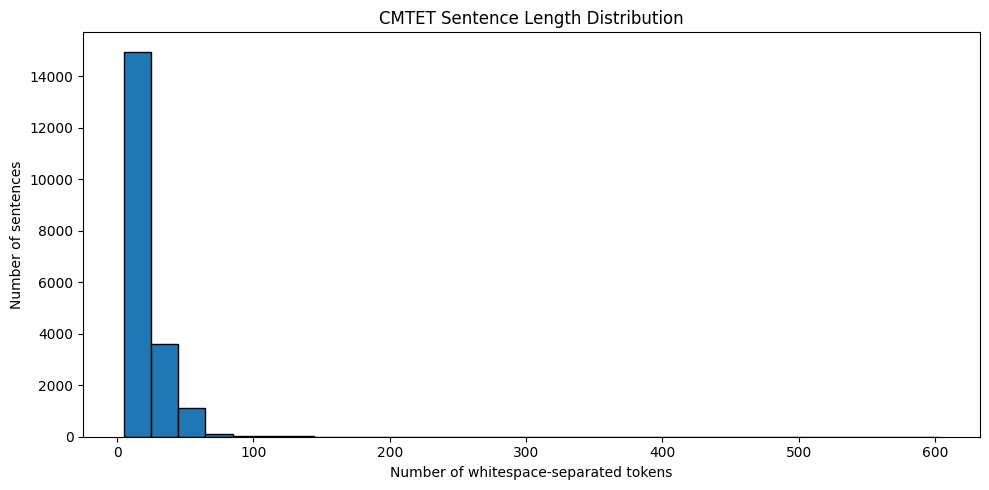

In [14]:
plt.figure(figsize=(10, 5))

plt.hist(df["token_count"], bins=30, edgecolor="black")

plt.title("CMTET Sentence Length Distribution")
plt.xlabel("Number of whitespace-separated tokens")
plt.ylabel("Number of sentences")

plt.tight_layout()
plt.show()

Compare sentence lengths by sentiment

Sentence length by sentiment:


,count,mean,median,min,max
sentiment,,,,,
NEG,7717,23.21,19.0,5,320
NTL,4222,12.23,9.0,5,244
POS,7929,18.39,13.0,5,603


<Figure size 800x500 with 0 Axes>

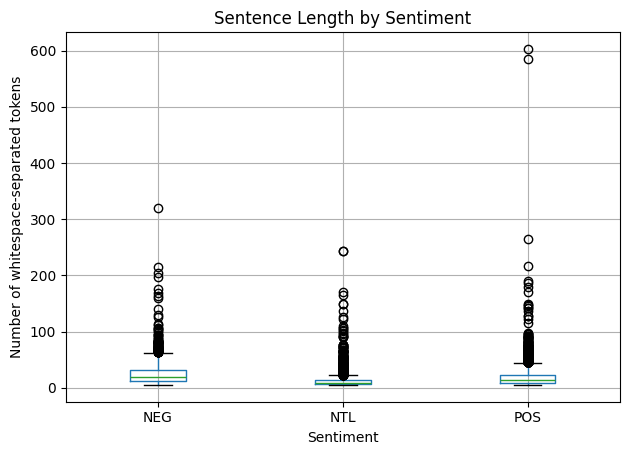

In [15]:
print("Sentence length by sentiment:")
display(
    df.groupby("sentiment")["token_count"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)

plt.figure(figsize=(8, 5))

df.boxplot(column="token_count", by="sentiment")

plt.title("Sentence Length by Sentiment")
plt.suptitle("")
plt.xlabel("Sentiment")
plt.ylabel("Number of whitespace-separated tokens")

plt.tight_layout()
plt.show()

# Analyze language composition

Count language tags

In [16]:
from collections import Counter

# Count all token-level language tags across the dataset
all_tags = Counter(
    tag
    for tags in df["language_tags"]
    for tag in tags
)

# Create a summary table
tag_summary = pd.DataFrame({
    "language_tag": list(all_tags.keys()),
    "token_count": list(all_tags.values())
})

tag_summary["percentage"] = (
    tag_summary["token_count"] / tag_summary["token_count"].sum()
) * 100

tag_summary = tag_summary.sort_values(
    "token_count", ascending=False
).reset_index(drop=True)

print("Total token-level tags:", sum(all_tags.values()))
display(tag_summary.round(2))

Total token-level tags: 376586


,language_tag,token_count,percentage
0,te,160286,42.56
1,en,130620,34.69
2,univ,70971,18.85
3,ne,14709,3.91


Visualize tag distribution

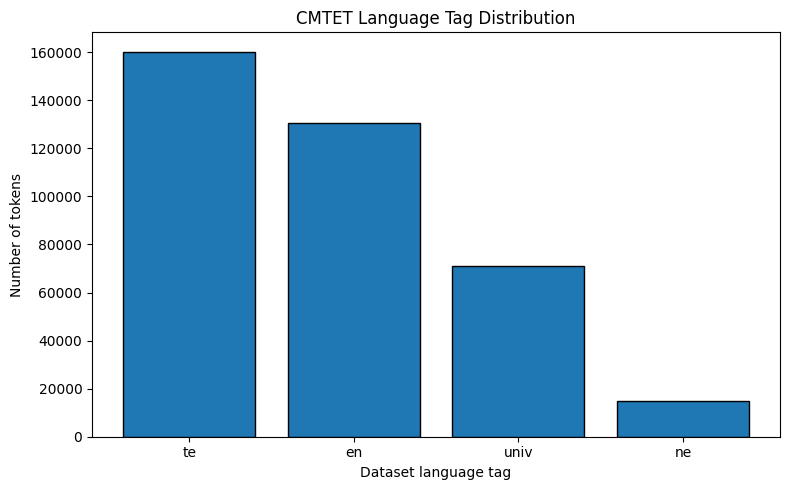

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    tag_summary["language_tag"],
    tag_summary["token_count"],
    edgecolor="black"
)

plt.title("CMTET Language Tag Distribution")
plt.xlabel("Dataset language tag")
plt.ylabel("Number of tokens")

plt.tight_layout()
plt.show()

Count tags at the sentence level

In [18]:
# Count sentences containing each tag at least once
sentence_tag_counts = Counter(
    tag
    for tags in df["language_tags"]
    for tag in set(tags)
)

sentence_tag_summary = pd.DataFrame({
    "language_tag": list(sentence_tag_counts.keys()),
    "sentences_containing_tag": list(sentence_tag_counts.values())
})

sentence_tag_summary["percentage_of_sentences"] = (
    sentence_tag_summary["sentences_containing_tag"] / len(df)
) * 100

sentence_tag_summary = sentence_tag_summary.sort_values(
    "sentences_containing_tag", ascending=False
).reset_index(drop=True)

display(sentence_tag_summary.round(2))

,language_tag,sentences_containing_tag,percentage_of_sentences
0,en,18794,94.59
1,te,17303,87.09
2,univ,16271,81.90
3,ne,8389,42.22
